## Notebook for loading, smoothing, and estimating PAR data 
- Uses radiometeter and satellite datasets

In [174]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# suppress warnings
import warnings
warnings.simplefilter('ignore')

### Load data

In [175]:
import re 

# define time resolution
timeres = '30min'
## calculate period based on 1 day
number = int(re.sub(r'\D', '', timeres)) # \D matches any non-digit character

# Read in TSD and rates data _{timeres}
tsd_path = f'/Users/Kathy/Library/CloudStorage/OneDrive-UW/Desktop/UW/seaflow/seaflow_tsd_project/data/all_seaflow_tsd_mixed_v1_all_{timeres}.pickle'
rates_path = f'/Users/Kathy/Library/CloudStorage/OneDrive-UW/Desktop/UW/seaflow/seaflow_tsd_project/data/final_rates_v1_all_{timeres}.pickle'

all_tsd = pd.read_pickle(tsd_path)
final_rates = pd.read_pickle(rates_path)

# make plots of log diel 
pop_cruise = all_tsd.copy()
pop_cruise['log_diel'] = np.log(pop_cruise['diel'])
all_cruises = pop_cruise['cruise'].unique()

#### Check that times and cruise days are aligned

In [194]:
## helper function start counting cruise days from the earliest time stamp
def align_cruise_populations(
    df,
    populations=None,
    freq="30min",
    duplicate_policy="raise",
):
    """
    Align population/model time series within each cruise.

    A single cruise start is defined as the earliest timestamp across
    all populations and models.

    Each existing population/model combination receives the same
    cruise-wide time grid.

    Original day labels are preserved in cruise_day_original.
    Newly inserted rows retain cruise, pop, model, and time, while
    original measurement columns remain NaN.
    """
    required = {"cruise", "pop", "model", "time", "time_of_day"}
    missing = required - set(df.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    if duplicate_policy not in {"raise", "first", "last"}:
        raise ValueError(
            "duplicate_policy must be 'raise', 'first', or 'last'."
        )

    if df.empty:
        raise ValueError("The input dataframe is empty.")

    data = df.copy()

    # Aware timestamps are converted to UTC.
    # Naive timestamps, if present, are interpreted as UTC.
    data["time"] = pd.to_datetime(
        data["time"],
        errors="raise",
        utc=True,
    )

    # Model is part of the observation identity.
    keys = ["cruise", "pop", "model", "time"]

    if data[keys].isna().any().any():
        raise ValueError(
            "cruise, pop, model, and time cannot contain "
            "missing values."
        )

    data["source_index"] = df.index.to_numpy()

    # Preserve original time-derived labels.
    for column in [
        "cruise_day",
        "day_hour",
        "cruise_hour",
        "hour_within_cruise_day",
    ]:
        if column in data.columns:
            original_column = f"{column}_original"

            if original_column in data.columns:
                raise ValueError(
                    f"{original_column} already exists. "
                    "Use the original, unaligned dataframe."
                )

            data = data.rename(
                columns={column: original_column}
            )

    # Rolling and STL records are NOT duplicates of each other.
    duplicate_mask = data.duplicated(
        subset=keys,
        keep=False,
    )

    duplicate_rows = (
        data.loc[duplicate_mask]
        .sort_values(keys)
        .copy()
    )

    if not duplicate_rows.empty:
        if duplicate_policy == "raise":
            raise ValueError(
                f"Found {len(duplicate_rows)} rows belonging to "
                "repeated cruise/pop/model/time keys.\n\n"
                + duplicate_rows.head(12).to_string(index=False)
                + "\n\nInspect these records before choosing "
                  "duplicate_policy='first' or 'last'."
            )

        data = data.drop_duplicates(
            subset=keys,
            keep=duplicate_policy,
        ).copy()

    step = pd.Timedelta(freq)

    if step <= pd.Timedelta(0):
        raise ValueError(
            "freq must be a positive fixed time interval."
        )

    requested_populations = (
        list(dict.fromkeys(populations))
        if populations is not None
        else None
    )

    data["_original_row_present"] = True
    results = []

    for cruise, group in data.groupby("cruise", sort=False):
        # Shared across ALL populations and models in the cruise.
        reference = group["time"].min()
        last_time = group["time"].max()

        elapsed = group["time"] - reference
        off_grid = (elapsed % step) != pd.Timedelta(0)

        if off_grid.any():
            raise ValueError(
                f"{cruise}: some timestamps do not lie on the "
                f"{freq} grid anchored at {reference}.\n"
                + group.loc[off_grid, keys]
                .head(12)
                .to_string(index=False)
            )

        if requested_populations is not None:
            omitted = (
                set(group["pop"]) - set(requested_populations)
            )

            if omitted:
                raise ValueError(
                    f"{cruise}: populations would be omitted: "
                    f"{sorted(omitted)}"
                )

        full_time = pd.date_range(
            start=reference,
            end=last_time,
            freq=freq,
            name="time",
        )

                # ----------------------------------------------------------
        # Create ONE shared sunrise-based timeline for this cruise.
        # ----------------------------------------------------------
        labels = group[["time", "time_of_day"]].copy()

        labels["time_of_day"] = (
            labels["time_of_day"]
            .astype("string")
            .str.strip()
            .str.lower()
            .replace("", pd.NA)
        )

        # Different populations/models should agree on the label
        # at the same timestamp. Missing labels are ignored.
        label_counts = (
            labels.groupby("time")["time_of_day"]
            .nunique(dropna=True)
        )

        conflicting_times = label_counts.loc[
            label_counts > 1
        ].index

        if len(conflicting_times):
            conflicting_rows = (
                labels.loc[
                    labels["time"].isin(conflicting_times)
                ]
                .drop_duplicates()
                .sort_values("time")
            )

            raise ValueError(
                f"{cruise}: conflicting time_of_day labels "
                "occur at the same timestamp. Resolve these "
                "before defining shared sunrise boundaries:\n"
                + conflicting_rows.head(20).to_string(index=False)
            )

        # Use the agreed nonmissing label at each timestamp.
        shared_labels = (
            labels.dropna(subset=["time_of_day"])
            .drop_duplicates(subset="time")
            .set_index("time")["time_of_day"]
            .reindex(full_time)
        )

        # For identifying consecutive sunrise labels only:
        # carry labels across unknown rows, but do not write those
        # inferred labels into the original measurement columns.
        labels_for_detection = shared_labels.ffill()

        is_sunrise = (
            labels_for_detection.eq("sunrise")
            .fillna(False)
            .astype(bool)
        )

        # The first timestamp in each sunrise run starts a new day.
        sunrise_start = (
            is_sunrise
            & ~is_sunrise.shift(1, fill_value=False)
        )

        # Number observed sunrise events.
        day_number = sunrise_start.cumsum().astype("int64")

        # The earliest available period is always day 0.
        # If the first timestamp is itself sunrise, it starts day 0,
        # rather than immediately starting day 1.
        day_number = day_number - int(day_number.iloc[0])

        # Actual observed sunrise time associated with each interval.
        sunrise_times = pd.Series(
            full_time,
            index=full_time,
        )

        day_start_time = (
            sunrise_times.where(sunrise_start).ffill()
        )

        timeline = pd.DataFrame(
            {
                "cruise_day": day_number,
                "sunrise_start": sunrise_start,
                "cruise_day_start_time": day_start_time,
                "shared_time_of_day": shared_labels,
            },
            index=full_time,
        )

        timeline.index.name = "time"

        if not sunrise_start.any():
            raise ValueError(
                f"{cruise}: no 'sunrise' labels were found. "
                "Cannot define sunrise-to-sunrise cruise days."
            )

        # Preserve existing population/model combinations.
        # Do not construct every possible pop × model combination.
        combinations = (
            group[["pop", "model"]]
            .drop_duplicates()
            .sort_values(["pop", "model"])
        )

        for pop, model in combinations.itertuples(
            index=False,
            name=None,
        ):
            series = group.loc[
                (group["pop"] == pop)
                & (group["model"] == model)
            ]

            full_index = pd.MultiIndex.from_product(
                [[cruise], [pop], [model], full_time],
                names=keys,
            )

            expanded = (
                series.set_index(keys)
                .reindex(full_index)
                .reset_index()
            )

            expanded["inserted_row"] = (
                expanded["_original_row_present"].isna()
            )

            expanded = expanded.drop(
                columns="_original_row_present"
            )

            expanded["cruise_start_time"] = reference

            # Map each population/model onto the shared timeline.
            expanded["cruise_day"] = (
                expanded["time"]
                .map(timeline["cruise_day"])
                .astype("int64")
            )

            expanded["sunrise_start"] = (
                expanded["time"]
                .map(timeline["sunrise_start"])
                .astype(bool)
            )

            expanded["cruise_day_start_time"] = (
                expanded["time"]
                .map(timeline["cruise_day_start_time"])
            )

            expanded["shared_time_of_day"] = (
                expanded["time"]
                .map(timeline["shared_time_of_day"])
            )

            # Fill a missing label only if another population/model
            # supplied a label at that exact timestamp.
            expanded["time_of_day"] = (
                expanded["time_of_day"]
                .combine_first(expanded["shared_time_of_day"])
            )

            # Total elapsed time since the first cruise observation.
            expanded["cruise_hour"] = (
                (
                    expanded["time"]
                    - reference
                ).dt.total_seconds()
                / 3600
            )

            # Time since the observed sunrise starting this day.
            # This is not calculated with modulo 24.
            expanded["hour_within_cruise_day"] = (
                (
                    expanded["time"]
                    - expanded["cruise_day_start_time"]
                ).dt.total_seconds()
                / 3600
            )

            results.append(expanded)

    aligned = (
        pd.concat(results, ignore_index=True)
        .sort_values(["cruise", "time", "pop", "model"])
        .reset_index(drop=True)
    )

    return aligned, duplicate_rows

In [195]:
# get time and cruise day aligned dataframe for each
aligned, duplicate_rows = align_cruise_populations(
    pop_cruise,
    populations=["prochloro", "synecho", "picoeuk"],
    freq="30min",
    duplicate_policy="first",
)

In [196]:
##### tests
# test_day = 4
# pop = 'synecho'
# cruise = 'CN11ID'
# model = 'STL'
# test_df = all_tsd.copy()
# test_df = aligned.copy()

# test_df.loc[(test_df['cruise_day_original'] == test_day) &
#             (test_df['pop'] == pop) & 
#             (test_df['cruise'] == cruise) &
#             (test_df['model'] == model)]

In [197]:
### Now align final_rates df
keys = ["cruise", "pop", "model", "cruise_day_original"]

# --------------------------------------------------------------
# 1. Prepare the original rates.
# --------------------------------------------------------------
rates = final_rates.loc[
    :, ~final_rates.columns.str.startswith("Unnamed:")
].copy()

if "cruise_day_original" in rates.columns:
    raise ValueError(
        "final_rates already contains cruise_day_original. "
        "Use the original rates dataframe to avoid relabeling twice."
    )

rates = rates.rename(
    columns={"cruise_day": "cruise_day_original"}
)

# Preserve any timestamp already present in the rates dataframe.
if "time" in rates.columns:
    rates = rates.rename(columns={"time": "rate_time_original"})

rates["cruise_day_original"] = pd.to_numeric(
    rates["cruise_day_original"],
    errors="raise",
)

# --------------------------------------------------------------
# 2. Prepare original observations from aligned.
# --------------------------------------------------------------
observations = aligned.copy()

observations["time"] = pd.to_datetime(
    observations["time"],
    utc=True,
    errors="raise",
)

observations["cruise_day_original"] = pd.to_numeric(
    observations["cruise_day_original"],
    errors="raise",
)

if "inserted_row" in observations.columns:
    observations = observations.loc[
        ~observations["inserted_row"].fillna(True)
    ].copy()

# Keep excluded records available for investigation.
required = keys + ["time", "cruise_day"]

excluded_observations = observations.loc[
    observations[required].isna().any(axis=1)
].copy()

observations = observations.dropna(subset=required)

# --------------------------------------------------------------
# 3. Select the first timestamp within each original rate day.
# --------------------------------------------------------------
first_times = (
    observations
    .sort_values("time")
    .drop_duplicates(subset=keys, keep="first")
    [keys + ["time", "cruise_day"]]
    .rename(columns={"time": "aligned_first_time"})
)

# --------------------------------------------------------------
# 4. Merge and identify actual matches.
# --------------------------------------------------------------
rates_aligned = rates.merge(
    first_times,
    on=keys,
    how="left",
    validate="many_to_one",
    indicator="day_merge",
    sort=False,
)

rates_aligned["day_mapping_found"] = (
    rates_aligned["day_merge"].eq("both")
)

rates_aligned["cruise_day"] = (
    rates_aligned["cruise_day"].astype("Int64")
)

# This is the timestamp selected from aligned, not the old rate time.
rates_aligned = rates_aligned.rename(
    columns={"aligned_first_time": "time"}
)

# --------------------------------------------------------------
# 5. Diagnose unmatched records.
# --------------------------------------------------------------
unmatched = rates_aligned.loc[
    ~rates_aligned["day_mapping_found"]
].copy()

print(f"Rate records: {len(rates_aligned)}")
print(f"Matched: {rates_aligned['day_mapping_found'].sum()}")
print(f"Unmatched: {len(unmatched)}")
print(
    "Observation rows excluded for missing keys/time/day:",
    len(excluded_observations),
)

if not unmatched.empty:
    # Test whether the original day exists for the cruise/population,
    # but under a different model.
    day_keys = ["cruise", "pop", "cruise_day_original"]

    available_days = (
        observations[day_keys]
        .drop_duplicates()
        .assign(day_exists_without_model=True)
    )

    unmatched_check = unmatched.merge(
        available_days,
        on=day_keys,
        how="left",
        validate="many_to_one",
    )

    unmatched_check["day_exists_without_model"] = (
        unmatched_check["day_exists_without_model"].eq(True)
    )

    print("\nUnmatched rate records:")
    print(
        unmatched_check[
            keys + ["day_exists_without_model"]
        ].to_string(index=False)
    )

Rate records: 1578
Matched: 1578
Unmatched: 0
Observation rows excluded for missing keys/time/day: 0


### Load SFL data

In [198]:
import os

# check if time resolution is in minutes
min_flag = 'min' in timeres
if min_flag:
    mins = int(number)
    # calculate hour fraction
    period = int((60 / mins) * 24)
    path = f'../data/30min_sfl.csv'
    # calculate period (how many hours in a day)
else: # otherwise, periodicty is hourly
    period = int((24 / number))
    path = '../data/hourly_sfl.csv'

# check if path exists
if os.path.exists(path):
    hourly_sfl = pd.read_csv(path)
    hourly_sfl['time'] = pd.DatetimeIndex(hourly_sfl['time']).tz_convert('UTC')

else:
    import requests
    from io import StringIO
    ## grab SFL files from seaflow repo
    # Set GitHub repo and directory
    REPO = "seaflow-uw/seaflow-sfl"
    DIR = "curated"
    BRANCH = "master"

    # GitHub API: get folder content
    url = f"https://api.github.com/repos/{REPO}/contents/{DIR}?ref={BRANCH}"
    response = requests.get(url)
    assert response.ok, f"GitHub API error: {response.text}"

    files = response.json()
    dataframes = []

    for file in files:
        # Only process files (skip directories if present)
        if file['type'] == 'file':
            raw_url = file['download_url']
            file_resp = requests.get(raw_url)
            assert file_resp.ok, f"Download error: {file_resp.text}"
            # Read as tab if needed
            df = pd.read_csv(StringIO(file_resp.text), sep="\t")
            # get cruise name
            filename = file['name']
            # extract name based on length
            if len(filename.split("_")) > 2:
                cutoff = 2
            else:
                cutoff = 1
            cruise = "_".join(filename.split("_")[:cutoff])
            print(cruise)
            df['cruise'] = cruise
            dataframes.append(df)

    # Concatenate all dataframess
    combined_df = pd.concat(dataframes, ignore_index=True)

    # grab correct cruise names
    seaflow_log = pd.read_csv('~/Desktop/UW/seaflow/decomposition_project/data/seaflow_log.csv')
    sfl_clean = seaflow_log[['cruise', 'Cruise ID']].merge(combined_df, left_on = 'cruise', right_on = 'cruise', how = 'outer')
    sfl_clean= sfl_clean.loc[sfl_clean['DATE'].notnull()].drop(columns = ['FILE', 'FILE DURATION', 'EVENT RATE', 'STREAM PRESSURE', 'SFL files in this directory have been validated and are ready for use in downstream SeaFlow analysis.', 'cruise', 'LAT', 'LON'])
    # clean up names 
    sfl_clean.rename(columns={'DATE': 'time', 'Cruise ID': 'cruise', 'OCEAN TEMP': 'SST'}, inplace=True)
    sfl_clean.columns = sfl_clean.columns.str.lower()
    # group by day
    sfl_clean['time'] = pd.DatetimeIndex(sfl_clean['time']).tz_convert('UTC')
    hourly_sfl = sfl_clean.groupby([pd.Grouper(key='time', freq=timeres), 'cruise']).mean().reset_index()
    # fix time
    hourly_sfl['time'] = pd.DatetimeIndex(hourly_sfl['time']).tz_convert('UTC')
    # save hourly sfl file
    hourly_sfl.to_csv(f'../data/{timeres}_sfl.csv', index=False)

#### Read in normalized PAR data (gridded data from pico)

In [199]:
 # read files with correction factors calcluated from satellite data
corrections = pd.read_csv('../data/gridded_par/par-calibration.csv')
corrections = corrections.loc[corrections['correction'].notnull()][['cruise', 'correction']]
# read in log
seaflow_log = pd.read_csv('~/Desktop/UW/seaflow/decomposition_project/data/seaflow_log.csv')
# get cruise names from log and remove nans
corr_clean = seaflow_log[['cruise', 'Cruise ID']].merge(corrections, 
                                                        left_on = 'cruise', right_on = 'cruise', 
                                                        how = 'outer')
corr_clean = corr_clean.loc[corr_clean['correction'].notnull()]
# rename cruise ID and cruise cols 
corr_clean.rename(columns = {'cruise': 'ID', 'Cruise ID': 'cruise'}, inplace = True)
# apply corrections to sfl data
corr_sfl = hourly_sfl.merge(corr_clean, how = 'left')
corr_sfl['norm_par'] = corr_sfl['par'] / corr_sfl['correction']

#### Correct offset cruises (4 found so far)
Need to do this before recalculating cruise days, otherwise PAR data will be lost

In [200]:
from zoneinfo import ZoneInfo
from timezonefinder import TimezoneFinder

## manually checked "bad" cruises
bad_times = ['KM1314', 'KM2103', 'KM2104', 'KOK1806'] # first 3 need offset of -10 hours, last one needs offset of -8 hours
bad_bad = ['TN291', 'KM2010', 'KM1709', 'TN271', 'KM2010'] # straight up BAD par data idk why this is in the curated SFL rip

# store in list
shifted_dfs = []
for cruise in bad_times:
    cruise_df = corr_sfl.loc[corr_sfl['cruise'] == cruise].sort_values(by = 'time')
    # offset par data
    offset = 10  # 10 hours but shift based on time resolution
    if cruise == 'KOK1806':
        offset = 8
    cruise_df['time'] = cruise_df['time'] - pd.Timedelta(hours = offset)
    # save shifted dataframe
    shifted_dfs.append(cruise_df)
# concatenate
shifted_df = pd.concat(shifted_dfs)
# subset
shifted_df = shifted_df[['cruise', 'time', 'par', 'norm_par']].drop_duplicates(subset = 'time')
# get cruises that are not offset
hot_cruise_offset = corr_sfl.loc[~corr_sfl['cruise'].isin(bad_times)]
# add back in
shifted_par = pd.concat([hot_cruise_offset, shifted_df]).reset_index(drop = True)

In [201]:
### double check all cruises align– yes they do yay
for cruise in shifted_df['cruise'].unique():
    cruise_df = corr_sfl.loc[corr_sfl['cruise'] == cruise].sort_values(by = 'time')
    shift_df = shifted_par.loc[shifted_par['cruise'] == cruise].sort_values(by = 'time')
    # plot
    fig, axs = plt.subplots(figsize = (10, 6), sharex = True)
    # plot OG par
    cruise_df['offset_time'] = pd.to_datetime(cruise_df['time']) - pd.Timedelta(hours = 10)
    axs.plot(cruise_df['offset_time'], cruise_df['par'], marker = 'o', c = 'goldenrod', alpha = 1)
    twinax = axs.twinx()
    # twinax.fill_between(cruise_df['time'], 0, 1, where = cruise_df['time_of_day'] == 'night',
    #                     color = 'gray', alpha = 0.5, transform = axs.get_xaxis_transform())
    # shifted PAR
    shift_df['offset_time'] = pd.to_datetime(shift_df['time']) - pd.Timedelta(hours = 10)
    axs.plot(shift_df['time'], shift_df['par'], marker = 'o', alpha = 0.5)

    axs.set_title(cruise)
    plt.tight_layout()
    plt.close()

### Merge SFL and rates data

In [202]:
# merge with colocalized rates
cruise_sfl = shifted_par.loc[shifted_par['cruise'].isin(all_cruises)]
# need to account for where PAR is missing (hopefully fix this in next iteration)
##### something bad happenign here #######
hot_cruise = aligned.drop(columns = ['par']).merge(shifted_par, how = 'left')

#### only retain cruise, cruise day, time, and par columns, then merge later to retrieve TSD component information for each model
# drop duplicates for cruises with 2 instruments and sort by time
cols = ['cruise', 'cruise_day', 'time', 'time_of_day', 'par', 'norm_par']
par_only = (hot_cruise[cols]
            .drop_duplicates(subset = ['cruise', 'cruise_day', 'time'])
            .sort_values(by = ['cruise', 'cruise_day', 'time'])
            .reset_index(drop = True)
            .sort_values(by = 'time'))
# drop duplicate cruises
par_only = par_only.loc[~par_only['cruise'].isin(['KM1906_tf', 'KM1923_740'])]
# create a column for each hour of each day (30 min resolution)
hour_conversion = 24 / period
par_only['day_hour'] = (par_only.groupby(['cruise', 'cruise_day']).cumcount() * hour_conversion)
# subset for diel cruise only 
diel_cruise = par_only.loc[par_only['cruise'] == 'KM1513'].drop(columns = ['par']).merge(corr_sfl)

In [211]:
### tests ####
### aligned df looks fine –– actually no it's starting counting from the earliest time rather than from sunrise
### rates_aligned good
### par_only looks bad– what is happening in the merge?
test = par_only.loc[(par_only['cruise'] == 'KM1314')] #& 
                #    (par_only['pop'] == 'picoeuk') & 
                #    (par_only['model'] == 'STL')]

days = [1]
res = test.loc[test['cruise_day'].isin(days)][['time', 'time_of_day', 'cruise_day']]

### Shift sunrise back by 1 hour
- solar calculator is based on sun angle
- actual PAR values start to increase about 1 hour before in Station ALOHA

*Think of starting sunrise based on PAR later on

In [212]:
# calculate 1 hour offset from period
hour_offset = int(period / 24)
pops = ['prochloro', 'synecho', 'picoeuk']

# save 
dfs = []
for cruise in par_only['cruise'].unique():
    df = par_only.loc[par_only['cruise'] == cruise].reset_index(drop=True).sort_values(by = 'time')
    df["time"] = pd.to_datetime(df["time"])
    # move sunrise one row up
    mask = df["time_of_day"] == "sunrise"
    # new sunrise rows (2 steps before the original sunrise)
    new_sunrise = mask.shift(-2, fill_value=False)
    # row between new_sunrise and original_sunrise (1 step before original sunrise)
    between = mask.shift(-1, fill_value=False)
    # 1) set the new sunrise position
    df.loc[new_sunrise, "time_of_day"] = "sunrise"
    # 2) rows between new and original sunrise should be day
    df.loc[between, "time_of_day"] = "day"
    # 3) original sunrise rows become day
    df.loc[mask, "time_of_day"] = "day"
    # update cruise days
    df.loc[df['time_of_day'] == 'sunrise', "cruise_day"] = df.loc[df['time_of_day'] == 'sunrise', "cruise_day"] + 1
    df.loc[between, "cruise_day"] = df.loc[between, "cruise_day"] + 1
    # recalculate day hour
    df['day_hour'] = (df.groupby(['cruise_day']).cumcount() * hour_conversion)
    # check for edge case such that day 1 starts before sunrise
    df_counts = (
    df.groupby(['cruise_day'])['time']
    .count()
    .reset_index()
    .sort_values('cruise_day')
    .reset_index(drop=True)
    )
    # check that df_counts not empty before shifting 
    if not df_counts.empty:
        day1_len = df_counts.loc[0, 'time']
        first_cruise_day = df_counts.loc[0, 'cruise_day']
        if day1_len < period:
            offset = period - day1_len
            df.loc[df['cruise_day'] == first_cruise_day, "day_hour"] += offset
    dfs.append(df)

par_only_new = pd.concat(dfs).reset_index(drop = True)

### recalculate day hours to accomodate incomplete days
RIght now this is shifting sunrise back 1 hour

In [213]:
## calculate hour per day starting from sunrise (hour 0)
# save 
empty_dfs = [] # save empty cruises
dfs = []
## debugging ########
# test_cruise = 'TN396'
# test_cruise_df = hot_cruise.loc[hot_cruise['cruise'] == test_cruise]
####################
for cruise in par_only_new['cruise'].unique():
    df = par_only_new.loc[par_only_new['cruise'] == cruise].sort_values(by = 'time')
    # skip if empty
    if df.empty:
        continue
    df["time"] = pd.to_datetime(df["time"])
    # recalculate day hour
    df['day_hour'] = (df.groupby(['cruise_day']).cumcount() * hour_conversion)
    # check for edge case such that day 1 starts before sunrise
    df_counts = df.groupby(['cruise_day'])['time'].count().reset_index()
    day1_len = df_counts.loc[0, 'time']
    first_cruise_day = df_counts.loc[0, 'cruise_day']
    # boolean for defining start of day (true if the first day starts at sunrise– full day)
    sunrise_start = df.loc[df['cruise_day'] == first_cruise_day, 'time_of_day'].values[0] == 'sunrise'
    # check for partial day on first day that doesn't start at sunrise
    if (~sunrise_start) &  (day1_len < period):
        # calculate offset
        # offset = 24 - day_len so that the first hour of that day gets this value
        offset = (period - day1_len) * hour_conversion
        # shift day_hour for the entire first group
        df.loc[df['cruise_day'] == first_cruise_day, "day_hour"] += offset
    dfs.append(df)
    
par_only_shift = pd.concat(dfs).reset_index(drop = True)
# ### bc of shift, need to filter out the days after in final_rates again
# keys = ['cruise', 'cruise_day', 'pop', 'model', 'daily_growth']
# # hot_cruise_shift = final_rates[keys].merge(hot_cruise_shift)

In [219]:
##### testing
cols = ['cruise', 'cruise_day', 'time', 'day_hour', 'time_of_day', 'par']
cruise = 'KM1906'
pop = 'prochloro'
days = [7, 8, 9, 10, 12]

test = par_only_shift.loc[(par_only_shift['cruise'] == cruise) & 
               (par_only_shift['cruise_day'].isin(days))][cols]

### testing
cols = ['cruise_day', 'time', 'time_of_day', 'day_hour', 'norm_par']
## double check cruise hours
df = hot_cruise.loc[(hot_cruise['cruise'] == 'KM1513')].reset_index(drop = True)
test = par_only_shift.loc[
                     (par_only_shift['cruise'] == 'KM1513')][cols].head(50)
# display(df[cols].head(50))
# display(test)

cruise = 'KM1314'
pop = 'prochloro'

data = par_only_shift.loc[
    (par_only_shift["cruise"] == cruise)
]

test = data.loc[
    (data["cruise"] == cruise)
].copy()
test.loc[test.duplicated(subset=["time"], keep=False)].sort_values("time")[cols]

# par_only_shift.loc[(par_only_shift['cruise'] == 'KM1314') & 
#                      (par_only_shift['cruise_day'] == 17)].groupby(['pop', 'time_of_day']).count()

# hot_cruise.loc[(hot_cruise['cruise'] == 'KM1314') &
#     (hot_cruise['pop'] == 'picoeuk')].sort_values(by = 'time')[['time', 'cruise_day', 'time_of_day']].groupby(['cruise_day']).count()

# fig, axs = plt.subplots()
# axs.plot(data['time'], data['log_diel'], marker = 'o')

,cruise_day,time,time_of_day,day_hour,norm_par


#### Filter out cruises with suspicious PAR values

In [227]:
import glob
from scipy import stats

files = sorted(glob.glob("../data/gridded_par/*.hourly_par.parquet"))

# --- Thresholds for flagging bad data (adjust as needed) ---
MAX_PAR_UPPER   = 3500   # physically unrealistic maximum (µmol photons m⁻² s⁻¹)
MIN_PAR_LOWER   = 0      # negative PAR is impossible
STD_TOO_LOW     = 10     # suspiciously flat signal (stuck sensor)
STD_TOO_HIGH    = 1500   # suspiciously noisy signal
NIGHT_PAR_MEAN  = 50     # threshold for night values being too high

results = []
n_cruises = len(files)
ncols = 3
nrows = int(np.ceil(n_cruises / ncols))

for cruise in par_only_shift['cruise'].unique():
    cruise_df = par_only_shift.loc[par_only_shift['cruise'] == cruise]
    par = cruise_df["norm_par"].dropna()

    par_min  = par.min()
    par_max  = par.max()
    par_mean = par.mean()
    par_std  = par.std()
    par_night_mean  = cruise_df.loc[cruise_df['time_of_day'] == 'night', 'norm_par'].mean()
    n        = len(par)

    # --- Flag logic ---
    flags = []
    if par_min < MIN_PAR_LOWER:
        flags.append("negative values")
    if par_max > MAX_PAR_UPPER:
        flags.append(f"max too high ({par_max:.0f})")
    if par_std < STD_TOO_LOW:
        flags.append(f"std too low ({par_std:.1f}) — possible stuck sensor")
    if par_std > STD_TOO_HIGH:
        flags.append(f"std too high ({par_std:.1f}) — possible noise")
    if par_night_mean > NIGHT_PAR_MEAN:
        flags.append(f"Night Mean PAR too high ({par_night_mean:.1f}) — possible noise")

    status = "BAD: " + "; ".join(flags) if flags else "OK"

    results.append({
        "cruise":   cruise,
        "n":        n,
        "min":      round(par_min, 2),
        "max":      round(par_max, 2),
        "mean":     round(par_mean, 2),
        "night_mean": round(par_night_mean, 2),
        "std":      round(par_std, 2),
        "status":   status,
    })

# --- Print summary table ---
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# --- Print only flagged cruises ---
bad = results_df[results_df["status"] != "OK"]
if not bad.empty:
    print("\n--- Flagged cruises ---")
    print(bad.to_string(index=False))
else:
    print("\nAll cruises passed QC checks.")

    cruise    n   min     max    mean  night_mean     std                                                                                                             status
     TN248    0   NaN     NaN     NaN         NaN     NaN                                                                                                                 OK
    W1005A    0   NaN     NaN     NaN         NaN     NaN                                                                                                                 OK
     TN252 1124  0.72 1127.64  235.11        0.75  307.50                                                                                                                 OK
     TN257  358  0.93 1186.37  192.99        0.93  313.45                                                                                                                 OK
     TN260  302  0.71  912.97  187.80        0.73  273.31                                                                              

In [228]:
# plot each bad cruise to manually check PAR– offset PAR are fixed above
for cruise in bad['cruise'].unique():
    # subset and get par data
    bad_cruise = par_only_shift.loc[par_only_shift['cruise'] == cruise].reset_index().head(500)
    # make diel plot
    fig, axs = plt.subplots(figsize = (10, 6))
    # plot daily par and diel cycle only for 1 cruise
    axs.plot(bad_cruise['norm_par'], marker = 'o', c = 'goldenrod', label = 'Corrected')
    # plot day night cycle
    twinax = axs.twinx()
    twinax.fill_between(bad_cruise['time'].index, 0, 1, where=bad_cruise['time_of_day'] == 'night',color='gray', alpha=0.3,
                            transform=axs.get_xaxis_transform())
    axs.legend(title = 'PAR type', loc = 'upper right')
    axs.set_title(f"{cruise}")
    plt.close()

In [ ]:
### time zone check
# check if bad_times cruises are in local tz instead of UTC
weird_times = hot_cruise_shift.loc[hot_cruise_shift['cruise'].isin(bad_times)]
test = weird_times.loc[weird_times['cruise'] == bad_times[-1]].reset_index(drop = True)

tf = TimezoneFinder()
# lat, lon = 36.968180, -150.000700
lat, lon = np.mean(test['lat']), np.mean(test['lon'])

tz_name = tf.timezone_at(lng=lon, lat=lat)
tz_name

# plot each bad cruise to manually check PAR
for cruise in weird_times['cruise'].unique():
    # subset and get par data
    bad_cruise = hot_cruise_shift.loc[hot_cruise_shift['cruise'] == cruise].reset_index().head(500)
    # make diel plot
    fig, axs = plt.subplots(figsize = (10, 6))
    # plot daily par and diel cycle only for 1 cruise
    axs.plot(bad_cruise['norm_par'], marker = 'o', c = 'goldenrod', label = 'Corrected')
    # plot day night cycle
    twinax = axs.twinx()
    twinax.fill_between(bad_cruise['time'].index, 0, 1, where=bad_cruise['time_of_day'] == 'night',color='gray', alpha=0.3,
                            transform=axs.get_xaxis_transform())
    axs.legend(title = 'PAR type', loc = 'upper right')
    axs.set_title(f"{cruise}")
    plt.close()

from zoneinfo import ZoneInfo
from timezonefinder import TimezoneFinder

tf = TimezoneFinder()
utc_time_str = test.loc[0, 'time']
utc_time, lat, lon = test.loc[test['time'] == 
                    utc_time_str][[
                    'time',
                    'lat', 
                    'lon'
                    ]].reset_index(drop = 
                                   True).iloc[0].values

# get time zone
timezone_name = tf.timezone_at(lat=lat, lng=lon)

# convert UTC tz to local
tz = tz_name # found with timezonefinder
local_time = utc_time.astimezone(ZoneInfo(timezone_name))
print(local_time)

In [229]:
# filter out cruises with bad or no PAR
empty = results_df.loc[results_df['mean'].isnull()]
## keep this for satellite PAR comparison
par_only_clean = par_only_shift.copy()
# set PAR values to nan for the cruises with bad PAR data
par_only_clean.loc[par_only_clean['cruise'].isin(bad_bad), ['par', 'norm_par']] = np.nan
## this is for when running against growth rates
# hot_cruise_clean = hot_cruise_shift.loc[(~hot_cruise_shift['cruise'].isin(bad_times)) & 
#                                          (~hot_cruise_shift['cruise'].isin(bad_bad)) & 
#                                         # (hot_cruise_shift['norm_par'].notnull()) & 
#                                         (~hot_cruise_shift['cruise'].isin(empty['cruise']))]
par_only_clean = par_only_clean.sort_values("time")
# hot_cruise_shift.to_csv('~/Downloads/all_30min_PAR.csv')

In [232]:
## testing
diel_cruise = par_only_clean.loc[par_only_clean['cruise'] == 'KM1314']
pro_test = diel_cruise.copy()#loc[diel_cruise['pop'] == 'prochloro'].reset_index(drop = True)
fig, axs = plt.subplots(figsize = (12, 6), nrows = 2, sharex = True)

axs[0].plot(pro_test['time'], pro_test['par'], marker = '.', c = 'goldenrod', label = 'Original')
axs[0].plot(pro_test['time'], pro_test['norm_par'], marker = '.', c = 'cyan', label = 'Normalized')
# axs[0].plot(pro_test['time'], pro_test['sat_par'], marker = '.', c = 'magenta', label = 'Model')
# plot day night cycle
twinax = axs[0].twinx()
twinax.fill_between(pro_test['time'], 0, 1, where=pro_test['time_of_day'] == 'night',color='gray', alpha=0.3,
                         transform = axs[0].get_xaxis_transform())

# axs[1].plot(pro_test['time'], pro_test['log_diel'], marker = '.')
axs[0].legend()
plt.tight_layout()
twinax = axs[1].twinx()
twinax.fill_between(pro_test['time'], 0, 1, where=pro_test['time_of_day'] == 'night',color='gray', alpha=0.3,
                         transform = axs[1].get_xaxis_transform())
plt.close()

### Smooth PAR data
- Using Savitzky-Golay filter applied to day-time only values (from perplexity)
- Fixing night time values to 0

In [59]:
import numpy as np
import pandas as pd
from scipy.signal import savgol_filter


def smooth_daily_par(
    df,
    cruise_day_col="cruise_day",
    datetime_col="time",
    par_col="norm_par",
    time_of_day_col="time_of_day",
    min_par=5,
    window_length=5,  # 5 samples = 2.5 hours at 2 samples/hour
    polyorder=2,
    output_col="norm_par_smooth",
):
    """
    Smooth PAR separately within each cruise_day (sunrise-to-sunrise).

    Values are set to zero when:
      - time_of_day == "night"
      - norm_par < min_par
      - norm_par is missing

    Only rows labeled "sunrise", "day", or "sunset" are smoothed.
    """

    out = df.copy()

    # Sort chronologically, but do not use calendar date for grouping.
    out[datetime_col] = pd.to_datetime(out[datetime_col])
    out = out.sort_values([cruise_day_col, datetime_col]).copy()

    # Standardize values used for logical masks.
    par = pd.to_numeric(out[par_col], errors="coerce")
    time_label = out[time_of_day_col].astype(str).str.lower().str.strip()

    # Define eligible daylight observations.
    is_daylight_label = time_label.isin(["sunrise", "day", "sunset"])
    is_night = time_label.eq("night")

    # Force values to zero if they are nighttime, below threshold, or missing.
    force_zero = is_night | par.lt(min_par) #| par.isna()

    out.loc[force_zero, par_col] = 0.0
    out[output_col] = 0.0

    # Smooth each sunrise-to-sunrise cruise_day independently.
    valid_daytime = is_daylight_label & ~force_zero

    for cruise_day, day_data in out.loc[valid_daytime].groupby(
        cruise_day_col,
        sort=False,
    ):
        idx = day_data.index
        y = out.loc[idx, par_col].to_numpy(dtype=float)

        # Savitzky–Golay requires an odd window no longer than the data segment.
        this_window = min(window_length, len(y))

        if this_window % 2 == 0:
            this_window -= 1

        # A valid Savitzky–Golay window must exceed polyorder.
        if this_window > polyorder:
            smoothed = savgol_filter(
                y,
                window_length=this_window,
                polyorder=polyorder,
                mode="interp",
            )
        else:
            smoothed = y

        # PAR cannot be negative.
        out.loc[idx, output_col] = np.clip(smoothed, 0, None)

    # Re-enforce physical/data-quality constraints after smoothing.
    out.loc[force_zero, output_col] = 0.0

    return out

In [ ]:
# run filter on par data
group_cols = ["cruise", "cruise_day"]
# get lat, lon data
par_only_clean_coords = (par_only_clean.merge(hot_cruise[['cruise', 'time', 'lat', 'lon']]
                                              .dropna()
                                              .drop_duplicates()
                                              )
                                        .reset_index(drop = True))

# keep bad data for now
hot_cruise_smooth = (
    # hot_cruise_clean
    par_only_clean_coords
    .groupby(group_cols, group_keys=False, sort=False)
    .apply(
        lambda group: smooth_daily_par(
            group,
            cruise_day_col="cruise_day",
            datetime_col="time",
            par_col="norm_par",
            time_of_day_col="time_of_day",
            min_par=5,
            window_length=9,
            polyorder=2,
            output_col="par_smooth",
        )
    )
)

## Plot some cruises to see how somoth they are
# plot each bad cruise to manually check PAR
for cruise in hot_cruise_smooth['cruise'].unique():
    # subset and get par data
    cruise_df = hot_cruise_smooth.loc[hot_cruise_smooth['cruise'] == cruise].reset_index().sort_values(by = 'time')
    # skip if empty
    if (cruise_df.loc[cruise_df['par'].notnull()].empty):
        continue
    # make diel plot
    fig, axs = plt.subplots(figsize = (10, 6))
    # plot daily par and diel cycle only for 1 cruise
    axs.plot(cruise_df['time'], cruise_df['par_smooth'], marker = 'o', c = 'goldenrod', label = 'Corrected')
    # plot day night cycle
    twinax = axs.twinx()
    twinax.fill_between(cruise_df['time'], 0, 1, where=cruise_df['time_of_day'] == 'night',color='gray', alpha=0.3,
                            transform=axs.get_xaxis_transform())
    axs.legend(title = 'PAR type', loc = 'upper right')
    axs.set_title(f"{cruise}")
    # plt.close()
        

In [237]:
## Try alternative PAR smoothing function that includes interpolation from clear sky model
import importlib
import sys
target_dir = os.path.abspath("../scripts/")
sys.path.insert(0, target_dir)
import par_quality
importlib.reload(par_quality)

# get lat, lon data
par_only_clean_coords = (par_only_clean.merge(hot_cruise[['cruise', 'time', 'lat', 'lon']]
                                              .dropna()
                                              .drop_duplicates()
                                              )
                                        .reset_index(drop = True))
processed_parts = []
# loop through each cruise
for cruise, sub in par_only_clean_coords.groupby(
    "cruise", sort=False
):
    result = par_quality.smooth_cruise_par(
        sub.drop_duplicates(subset = 'time').reset_index(drop = True),
        cruise_col="cruise",
        cruise_day_col="cruise_day",
        datetime_col="time",
        norm_par_col="norm_par",
        par_col="par",
        lat_col="lat",
        lon_col="lon",
        output_col="norm_par_smooth",
        freq="30min",
        fill_grid=True,
        window_length=9,
        polyorder=2,
        remove_outliers=True,
        outlier_n_mads=6.0,
        night_elevation_deg=-6.0,
        clearsky_coefficient=2200.0,
        clearsky_index_fallback=0.55,
        scale_model_to_observations=True,
    )

    processed_parts.append(result)

processed = pd.concat(
    processed_parts,
    ignore_index=True,
)

# processed = []
# for cruise, sub in par_only_clean_coords.groupby("cruise", sort=False):
#     r = par_quality.smooth_daily_par(
#         sub.drop_duplicates(subset = 'time').reset_index(drop = True),
#         cruise_col="cruise", cruise_day_col="cruise_day",
#         datetime_col="time", par_col="norm_par",
#         time_of_day_col="time_of_day", lat_col="lat", lon_col="lon",
#         min_par=5.0,
#         window_length=9,   # 4.5 h; use 5 (2.5 h) to preserve more detail
#         polyorder=2,
#         output_col="norm_par_smooth",
#     )
#     processed.append(r)

# # processed PAR data- norm_par_smooth is final imputed, smoothed col
# processed = pd.concat(processed, ignore_index=True)

#### Calculate daily integrated PAR for each day in cruise
- In units of µE  / sec m2
- Start from sunrise to sunset

In [238]:
for cruise in processed['cruise'].unique():
    cruise_df = processed.loc[processed['cruise'] == cruise]
    # save int par in dfs
    if cruise_df.empty:
        continue
    ## integrate starting from sunrise
    # convert from seconds to hours
    cruise_df['hourly_par'] = cruise_df['norm_par_smooth'] * 3600
    cruise_df['int_par'] = cruise_df.groupby('cruise_day')['hourly_par'].cumsum()
    # reset night values to 0
    cruise_df.loc[cruise_df['time_of_day'] == 'night', 'int_par'] = 0
    # set int_par col in hot_cruise df
    processed.loc[cruise_df.index, 'int_par'] = cruise_df['int_par']
# hot_cruise_smooth.head(50)[['cruise', 'pop', 'time', 'cruise_day', 'par_smooth', 'time_of_day']]

#### Plot processed PAR and manually inspect

In [241]:
## Plot some cruises to see how somoth they are
test_cruises = processed['cruise'].unique()#['TN291']
# plot each bad cruise to manually check PAR
for cruise in test_cruises:
    # subset and get par data
    cruise_df = processed.loc[processed['cruise'] == cruise].reset_index().sort_values(by = 'time')
    # skip if empty
    if (cruise_df.loc[cruise_df['norm_par_smooth'].notnull()].empty):
        continue
    # make diel plot
    fig, axs = plt.subplots(figsize = (10, 6))
    # plot daily par and diel cycle only for 1 cruise
    axs.plot(cruise_df['time'], cruise_df['norm_par_smooth'], marker = 'o', c = 'cyan', label = 'Corrected')
    axs.plot(cruise_df['time'], cruise_df['par'], marker = 'o', c = 'goldenrod', label = 'Original')
    axs.legend()
    # plot day night cycle
    twinax = axs.twinx()
    twinax.fill_between(cruise_df['time'], 0, 1, where=cruise_df['time_of_day'] == 'night',color='gray', alpha=0.3,
                            transform=axs.get_xaxis_transform())
    axs.legend(title = 'PAR type', loc = 'upper right')
    axs.set_title(f"{cruise}")
    # plt.show()
    plt.close()

### Merge PAR data with rates information
- Flag rows for Qc check
- 0 if pass, 1 if fail

In [309]:
# merge back with final rates to get model and population specific TSD compoennts
### bc of shift, need to filter out the days after in final_rates again
keys = ['cruise', 'cruise_day', 'pop', 'model', 'daily_growth']
qc_lookup = rates_aligned[keys]
# merge to get tsd level data– time of day should be based on processed df
tsd_info = (hot_cruise[['time', 'cruise', 'pop', 
                        'model', 'lat', 'lon', 'diel', 'log_diel', 'trend', 
                        'resid', 'data_with_missing']]
            .drop_duplicates())
tsd_shift = tsd_info.merge(processed.drop(columns = ['lat', 'lon']), how = 'left')
no_par_cruises = tsd_shift.loc[tsd_shift['time_of_day'].isnull(), 'cruise'].unique() # only KM1923_740 and TN252
# set flag for Qc based on rates_aligned (TSD-PP Qc criteria)
hot_cruise_shift = tsd_shift.merge(
    qc_lookup,
    on= ['cruise', 'cruise_day', 'pop', 'model'],
    how="left",
    indicator="qc_merge",
)
# flag: 0 = matching combination exists in rates_aligned, 1 = no matching combination exists
hot_cruise_shift["qc_flag"] = (
    hot_cruise_shift["qc_merge"].ne("both").astype("int8")
)

In [324]:
##### testing ######
# display(processed.loc[(processed['cruise'] == 'KM1314') & 
#               (processed['time'] == '2013-08-10 12:00:00+00:00')][['time_of_day', 'solar_elev']])

# hot_cruise_shift.loc[(hot_cruise_shift['cruise'] == 'KM1314') & 
#                    (hot_cruise_shift['cruise_day'] == 1) & 
#                    (hot_cruise_shift['pop'] == 'prochloro')][['time', 'cruise', 'cruise_day', 'time_of_day', 'log_diel', 'norm_par_smooth', 'qc_flag']]

#### Save data for growth rate calculations
- This currently has "bad" par data in it, need to switch back to `hot_cruise_clean` to remove bad data

In [325]:
# save PAR only data
processed.to_csv(f'../data/smoothed_par_data/par_only_smoothed_{timeres}.csv')
rates_aligned.to_csv(f'../data/smoothed_par_data/rates_aligned_{timeres}.csv')
# save flagged PAR data
hot_cruise_shift.to_pickle(f'../data/smoothed_par_data/hot_cruise_smooth_{timeres}.pickle')

In [ ]:
####### previously processed PAR data #########
# read in CSV (for R)
hot_cruise_smooth.reset_index(drop = True).to_csv(f'../data/smoothed_par_data/hot_cruise_smooth_{timeres}.csv')
# pickle (for Python)
hot_cruise_smooth.reset_index(drop = True).to_pickle(f'../data/smoothed_par_data/hot_cruise_smooth_{timeres}.pickle')
# also save cruises with "bad" PAR data
bad.reset_index(drop = True).to_csv(f'../data/smoothed_par_data/bad_par_cruises_{timeres}.csv', index = False)
bad.reset_index(drop = True).to_pickle(f'../data/smoothed_par_data/bad_par_cruises_{timeres}.pickle')

In [69]:
m_df = (hot_cruise_smooth[['cruise', 'cruise_day', 'time', 'time_of_day', 'lat', 'lon', 'par', 'norm_par', 'par_smooth']]
 .drop_duplicates(subset = 'time')
 .reset_index(drop = True))
# create an identifier column for each cruise, cruise day
m_df['id'] = m_df.groupby(['cruise', 'cruise_day']).ngroup() + 1
m_df.to_csv('~/Downloads/par_testing.csv')

## Testing 
- Checking Diel cruise PAR data
- Download surface and depth PAR data from hyperpro profiles and compare 

Text(0.5, 1.0, 'KM1513 Daily Hourly PAR')

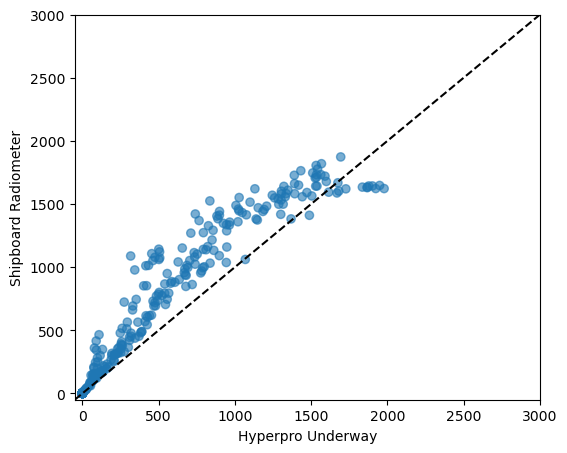

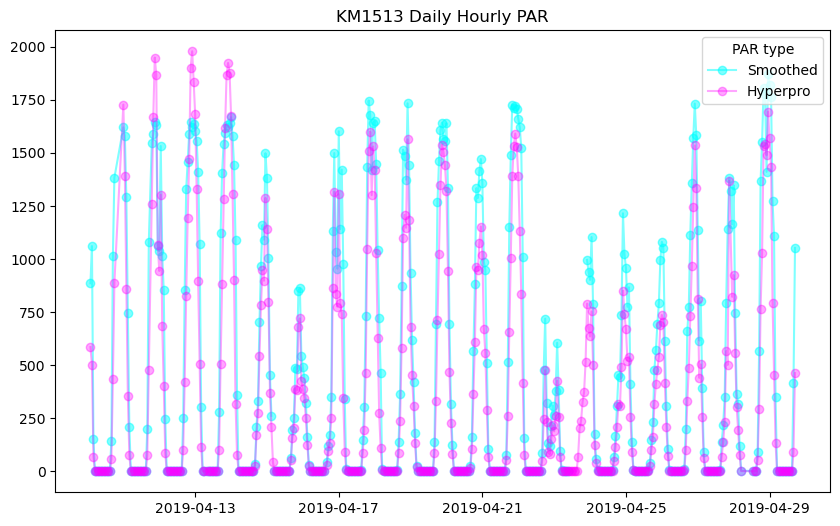

In [17]:
import pycmap 
from dotenv import load_dotenv
import os

# grab API key from hidden file
load_dotenv()
api_key = os.getenv("API_KEY")  
api = pycmap.API(token= api_key)

# download an underway hyperpro dataset (G3)
g3_hyperpro = api.query("""
    SELECT time, lat, lon, surface_par
    FROM tblKM1906_Gradients3_Hyperpro
""")
g3_hyperpro['time'] = pd.DatetimeIndex(g3_hyperpro['time']).tz_localize('UTC')
g3_grouped = g3_hyperpro.groupby([pd.Grouper(key = 'time', freq = timeres)]).mean().reset_index()
# specify PAR column
g3_grouped.rename(columns = {"surface_par": "hyperpro_par"}, inplace = True)


## compare g3 hyperpro data and shipboard radiometer data
g3_df = corr_sfl.loc[corr_sfl['cruise'] == 'KM1906']
# plot sat normalized par with hyperpro data
g3_merged = g3_df.merge(g3_grouped)

# plot 1:1 comparison
fig, axs = plt.subplots(figsize = (6, 5))
# par
axs.scatter(g3_merged['hyperpro_par'], g3_merged['norm_par'], linestyle = '', alpha = 0.6)
# 1:1 line
lims = (-50, 3000)
axs.plot(lims, lims, linestyle = '--', c = 'k')
# set x and y lims
axs.set_xlim(lims)
axs.set_ylim(lims)
# labels
axs.set_xlabel("Hyperpro Underway")
axs.set_ylabel("Shipboard Radiometer")


# # plot daily par and diel cycle only for 1 cruise
fig, axs = plt.subplots(figsize = (10, 6))
# axs.plot(g3_merged['time'], marker = 'o', c = 'goldenrod', label = 'Corrected')
axs.plot(g3_merged['time'], g3_merged['norm_par'], marker = 'o', c = 'cyan', alpha = 0.5, label = 'Smoothed')
g3_merged = g3_merged.loc[g3_merged['hyperpro_par'] < 3000]
axs.plot(g3_merged['time'], g3_merged['hyperpro_par'], marker = 'o', c = 'magenta', alpha = 0.35, label = 'Hyperpro')

axs.legend(title = 'PAR type', loc = 'upper right')
axs.set_title("KM1513 Daily Hourly PAR")

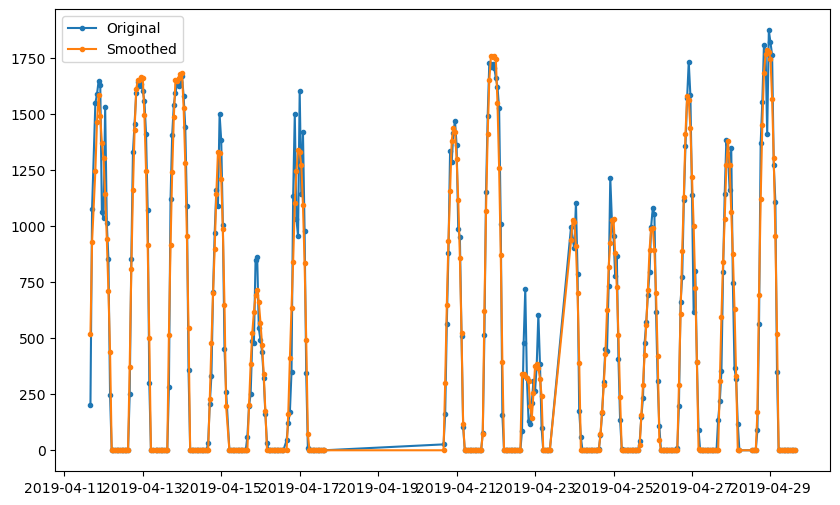

In [18]:
###### testing ######
test = hot_cruise_smooth.loc[(hot_cruise_smooth['cruise'] == 'KM1906') & 
                             (hot_cruise_smooth['pop'] == 'prochloro')]

# plot original and smoothed data
fig, axs = plt.subplots(figsize = (10, 6))
axs.plot(test['time'], test['norm_par'], marker = '.', label = 'Original')
axs.plot(test['time'], test['par_smooth'], marker = '.', label = 'Smoothed')
# axs.plot(test['time'], test['par_smooth'], marker = '.', label = 'Smoothed')
axs.legend()

In [73]:
cruise = 'KM1906'
day = [9, 10, 11]
hot_cruise_smooth.loc[(hot_cruise_smooth['cruise'] == cruise) & 
                      (hot_cruise_smooth['cruise_day'].isin(day))]

,cruise,cruise_day,pop,model,daily_growth,hour,diel,trend,resid,time,...,salinity,sst,par,bulk red,ID,correction,norm_par,day_hour,par_smooth,int_par
21980,KM1906,11.0,prochloro,Rolling,0.008615,526.0,0.892789,0.041263,0.939638,2019-04-21 16:00:00+00:00,...,34.862067,17.064617,43.517683,26.696133,KM1906,1.157,37.612518,0.0,0.000000,0.000000e+00
21981,KM1906,11.0,prochloro,Rolling,0.008615,527.0,0.914540,0.040706,0.966075,2019-04-21 16:30:00+00:00,...,34.907880,17.217010,119.392820,21.878800,KM1906,1.157,103.191720,0.5,196.187728,7.062758e+05
21982,KM1906,11.0,prochloro,Rolling,0.008615,528.0,0.896735,0.040178,0.983431,2019-04-21 17:00:00+00:00,...,34.898720,17.249550,240.891560,21.878800,KM1906,1.157,208.203596,1.0,475.292259,2.417328e+06
21983,KM1906,11.0,prochloro,Rolling,0.008615,529.0,0.874253,0.039683,1.047539,2019-04-21 17:30:00+00:00,...,34.882510,17.232900,952.413810,21.878800,KM1906,1.157,823.175290,1.5,734.706642,5.062272e+06
21984,KM1906,11.0,prochloro,Rolling,0.008615,530.0,0.886223,0.039182,1.051198,2019-04-21 18:00:00+00:00,...,34.876230,17.177140,1397.607480,23.191030,KM1906,1.157,1207.958064,2.0,974.430877,8.570223e+06
21985,KM1906,11.0,prochloro,Rolling,0.008615,531.0,0.884060,0.038637,1.062768,2019-04-21 18:30:00+00:00,...,34.899990,17.159700,1267.483200,21.157200,KM1906,1.157,1095.491098,2.5,1247.863781,1.306253e+07
21986,KM1906,11.0,prochloro,Rolling,0.008615,532.0,0.862169,0.038080,0.960977,2019-04-21 19:00:00+00:00,...,34.909800,17.203440,1664.901980,21.157200,KM1906,1.157,1438.981832,3.0,1458.724454,1.831394e+07
21987,KM1906,11.0,prochloro,Rolling,0.008615,533.0,0.856232,0.037535,0.963622,2019-04-21 19:30:00+00:00,...,34.896830,17.166910,1781.010250,21.157200,KM1906,1.157,1539.334702,3.5,1557.016712,2.391920e+07
21988,KM1906,11.0,prochloro,Rolling,0.008615,534.0,0.893016,0.037052,1.024631,2019-04-21 20:00:00+00:00,...,34.897800,17.205590,1996.084880,21.157200,KM1906,1.157,1725.224615,4.0,1642.737510,2.983306e+07
21989,KM1906,11.0,prochloro,Rolling,0.008615,535.0,1.016318,0.036613,1.323784,2019-04-21 20:30:00+00:00,...,34.898450,17.205110,2002.769990,21.157200,KM1906,1.157,1731.002584,4.5,1727.144243,3.605078e+07


In [19]:
### old method of smoothing PAR- rolling average

# # filter out cruises with bad PAR
# hot_cruise_clean = hot_cruise_new_shift.loc[~hot_cruise_new_shift['cruise'].isin(bad['cruise'])]

# # testing
# hot_cruise_clean = hot_cruise_clean.sort_values("time")

# hot_cruise_clean["par_smooth"] = (
#     hot_cruise_clean.groupby(["cruise", "cruise_day", 'pop'])["norm_par"]
#             .transform(lambda x: x.rolling(window=5, center=True, min_periods=1).median())
# )

# hot_cruise_clean["par_smooth"] = (
#     hot_cruise_clean.groupby(["cruise", "cruise_day", 'pop'])["norm_par"]
#             .transform(lambda x: x.smooth_daily_par(
#     test,
#     datetime_col="time",
#     par_col="norm_par",
#     time_of_day_col="time_of_day",
#     min_par=5,
#     window_length=9,
#     polyorder=2,
#     output_col="norm_par_smooth",
# ))
# )

# # second pass smoothing
# hot_cruise_clean["par_smooth"] = (
#     hot_cruise_clean.groupby(["cruise", "cruise_day", 'pop'])["norm_par"]
#     .transform(lambda x: x.rolling(window=3, center=True, min_periods=1).mean())
# )

# # set all night time values to 0
# hot_cruise_clean.loc[hot_cruise_clean['time_of_day'] == 'night', 'par_smooth'] = 0

### What does PAR look like for each day of the diel cruise?

Text(0.5, 1.0, 'KM1513 Daily Hourly PAR')

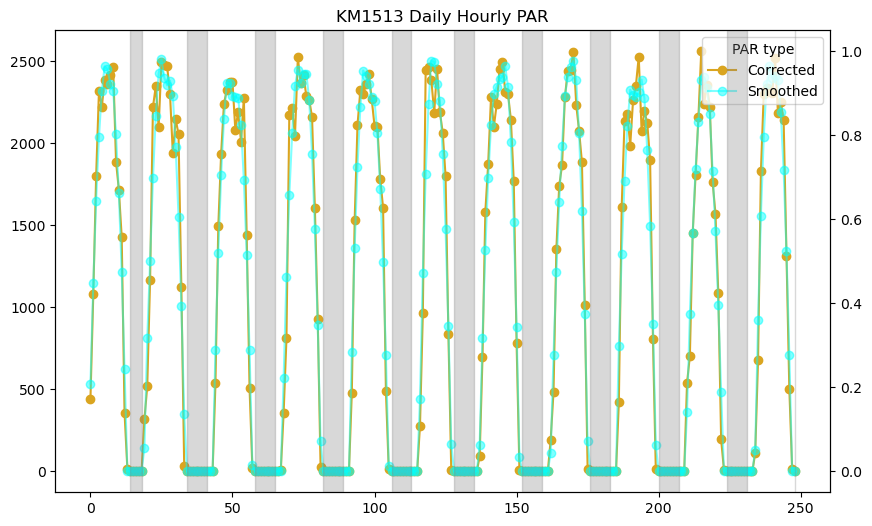

In [20]:
uniq_cruise = hot_cruise_smooth.loc[hot_cruise_smooth['cruise'] == 'KM1513'].drop_duplicates(subset = ['time', 'par']).reset_index()
# fix par such that there are no positive values during the night
# uniq_cruise.loc[(uniq_cruise['par'] > 0) & (uniq_cruise['time_of_day'] == 'night'), 'par'] = 0

# # plot daily par and diel cycle only for 1 cruise
fig, axs = plt.subplots(figsize = (10, 6))
axs.plot(uniq_cruise['norm_par'], marker = 'o', c = 'goldenrod', label = 'Corrected')
axs.plot(uniq_cruise['par_smooth'], marker = 'o', c = 'cyan', alpha = 0.5, label = 'Smoothed')
# plot day night cycle
twinax = axs.twinx()
twinax.fill_between(uniq_cruise['time'].index, 0, 1, where=uniq_cruise['time_of_day'] == 'night',color='gray', alpha=0.3,
                         transform=axs.get_xaxis_transform())
axs.legend(title = 'PAR type', loc = 'upper right')
axs.set_title("KM1513 Daily Hourly PAR")
# plt.close()

#### what does PAR look like across each hour of the day?

In [21]:
# sort df
par_df = uniq_cruise.sort_values(by = 'day_hour')
fig, axs = plt.subplots(figsize = (8, 8), nrows = 2, sharex = True)
twinax = axs[0].twinx()
# show night/day
twinax.fill_between(par_df['day_hour'], 0, 1, where=par_df['time_of_day'] == 'night',color='gray', alpha=0.3,
                         transform=axs[0].get_xaxis_transform())

axs[0].plot(par_df['day_hour'], par_df['par_smooth'], marker = '.', c = 'goldenrod')
axs[0].set_ylabel('PAR')

## what time does it actually look like diel Qc is starting to increase? 
pro_df = diel_cruise.loc[diel_cruise['pop'] == 'prochloro']
# sort 
pro_df = pro_df.sort_values(by='day_hour')
axs[1].plot(pro_df['day_hour'], pro_df['log_diel'], marker = '.')
twinax = axs[1].twinx()
twinax.fill_between(pro_df['day_hour'], 0, 1, where=pro_df['time_of_day'] == 'night',color='gray', alpha=0.3,
                         transform=axs[1].get_xaxis_transform())
axs[1].set_ylabel('Diel Qc')
axs[1].set_xlabel('Hour')
plt.tight_layout()
plt.close()

#### How does integrated PAR vary by hour?
- Box plot of hourly integrated PAR

Text(0, 0.5, 'Integrated PAR (µE m2)')

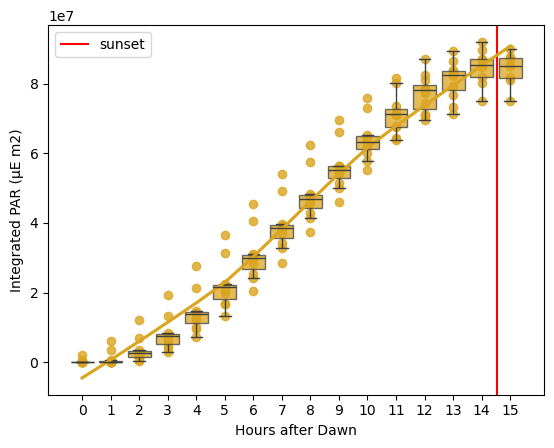

In [22]:
# extract date for grouping
test_day = hot_cruise_smooth.loc[hot_cruise_smooth['cruise'] == 'KM1513'].drop_duplicates(subset = ['time', 'par']).reset_index()
test_day['date'] = test_day['time'].dt.date
# create day_hour 0–23 within each day, ordered by time
test_day['day_hour'] = test_day.groupby('cruise_day').cumcount()
# create plot object
fig, axs = plt.subplots()
# box plot
c = 'goldenrod'
sns.boxplot(test_day.loc[test_day['time_of_day'] != 'night'], 
        x = 'day_hour', y = 'int_par', showfliers = False, 
        boxprops={'facecolor': c, 'alpha': 0.75}, ax = axs)
sunset_hour = np.mean(test_day.loc[test_day['time_of_day'] == 'sunset', 'day_hour'])
plt.axvline(x = sunset_hour, c = 'r', label = 'sunset')

# figure with lowess
sns.regplot(test_day.loc[test_day['time_of_day'] != 'night'], 
        x = 'day_hour', y = 'int_par', lowess= True, ax = axs, 
        scatter_kws={"color": c}, line_kws={'color': c})
plt.legend()

plt.xlabel('Hours after Dawn')
plt.ylabel('Integrated PAR (µE m2)')